# Ballroom rhythm classification: SVM–RBF

**Question:** How well do rhythm features tell the eight Ballroom dance styles apart, how much of that comes from tempo alone, and what happens when only the tempo of the audio changes?

This notebook evaluates two feature sets with **SVM–RBF**, using exactly the same folds, tuning and time-stretched audio as the timbral notebooks:

| Feature set | Inputs | Meaning |
|---|---|---|
| **Rhythm** | 20 | cyclic tempogram (15), bar ratios (3), PLP confidence and PLP alignment (2) |
| **Tempo only** (baseline) | 1 | `tau_hat`, the tempo estimated from the audio |

Steps:

1. find the clips and make the same 5 test folds as the timbral notebooks,
2. compute the rhythm features of every clip in 13 versions (original, 6 stretches, 6 round trips),
3. train a default and a tuned model on the original clips (nested cross-validation), for each feature set,
4. evaluate them on the original audio, then on the stretched and round-trip audio,
5. compare timbral, rhythm and tempo-only, which answers the question of the README.

The notebook `Rhythm_Random_Forest.ipynb` does the same with Random Forest. Only sections 7 and 11 (the model) differ; if you change any other section, change it in both.

> **Earlier run, kept for reference.** This run used the updated rhythm extraction with a tempo range of 60–220 BPM, the value set in `src/Rythm_extraction.py`. The main run now uses 60–280 BPM: with 220 BPM, fast dances stretched by +10% (for example Quickstep at about 204–211 BPM, which becomes 224–232 BPM) go over the limit and the tempo estimate is forced to jump. The notebook paths point to the main project folder, so this copy is a record and is not meant to be run from here.

## 1. Files

```
project folder/
├── BallroomData/ (or another folder, see DATASET_DIR)   the audio, needed from the start
├── folds.csv                         made by the timbral notebooks (made here if missing)
├── ballroom_rhythm_features.csv      the earlier rhythm features (only used for a comparison)
├── results/random_forest/, results/svm_rbf/   the timbral results (used in section 19)
├── Rhythm_Random_Forest.ipynb
└── Rhythm_SVM_RBF.ipynb
```

| Written by this notebook | What it is |
|---|---|
| `rhythm_conditions.csv` | rhythm features of every clip in all 13 versions. Computed once by whichever rhythm notebook runs first, then reused by the other |
| `results/rhythm_svm_rbf/rhythm/`, `.../tempo_only/` | tables and figures of each feature set |
| `results/rhythm_svm_rbf/comparison/` | the comparison of timbral, rhythm and tempo-only |

In [1]:
from dataclasses import dataclass, field
from pathlib import Path
import os
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from scipy.interpolate import interp1d
from scipy.signal import get_window
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# librosa 1.0 warns about arguments it passes to itself inside time_stretch; harmless, so hidden
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Configuration

Change settings here before running, and write down any change.

In [2]:
PROJECT_DIR = Path('.')                                     # the folder with the notebooks and folds.csv
DATASET_DIR = Path('BallroomData')                       # the folder with the dance folders

MODEL_NAME = 'SVM–RBF'
OTHER_MODEL_NAME = 'Random Forest'
FOLDS_PATH = PROJECT_DIR / 'folds.csv'                      # shared with the timbral notebooks
CONDITIONS_PATH = PROJECT_DIR / 'rhythm_conditions.csv'     # shared by both rhythm notebooks
EARLIER_CSV = PROJECT_DIR / 'ballroom_rhythm_features.csv'  # only for a comparison in section 6
RESULTS_DIR = PROJECT_DIR / 'results' / 'rhythm_svm_rbf'
OTHER_RESULTS_DIR = PROJECT_DIR / 'results' / 'rhythm_random_forest'
TIMBRAL_RESULTS_DIR = PROJECT_DIR / 'results' / 'svm_rbf'

EXPECTED_CLIPS = 698
RANDOM_SEED = 2026
OUTER_FOLDS = 5
INNER_FOLDS = 3
N_JOBS = 8                          # CPU cores; set to 1 if parallel runs give problems
IMPORTANCE_REPEATS = 5

VARIANTS = ['Default', 'Tuned']
METRICS = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # first, second and third series in every plot
MODEL_COLORS = {'Random Forest': BLUE, 'SVM–RBF': ORANGE}
SET_COLORS = {'Timbral': BLUE, 'Rhythm': ORANGE, 'Tempo only': AQUA}
SET_DIRS = {'Rhythm': 'rhythm', 'Tempo only': 'tempo_only'}

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f'{DATASET_DIR} not found. The rhythm notebooks compute their features from the '
                            'audio, so set DATASET_DIR to the BallroomData folder.')
for folder in list(SET_DIRS.values()) + ['comparison']:
    (RESULTS_DIR / folder / 'time_stretch').mkdir(parents=True, exist_ok=True)


def save(table, feature_set, name, **options):
    table.to_csv(RESULTS_DIR / SET_DIRS.get(feature_set, feature_set) / name, **options)


def save_figure(figure, feature_set, name):
    figure.savefig(RESULTS_DIR / SET_DIRS.get(feature_set, feature_set) / name, bbox_inches='tight')
    plt.show()

## 3. The clips and the five test folds

The clips are found directly in `BallroomData/`: every `.wav` file in a dance folder (hidden files such as macOS `._` files are skipped). The folder name is the label, and the three Rumba folders are one class. `nada/` and `allBallroomFiles` contain no audio.

The folds are made exactly as in the timbral notebooks: **stratified** (every fold has about the same share of each genre) and **grouped** (the 13 known pairs of repeated recordings stay in one fold). If `folds.csv` already exists, the cell checks that it gets exactly the same folds, so the rhythm, tempo-only and timbral models are tested on the same clips.

In [3]:
KNOWN_REPLICAS = [   # 13 known pairs of repeated recordings; Fire-08 / Fire-09 is the same audio with two labels
    ('Albums-AnaBelen_Veneo-11.wav', 'Albums-Chrisanne2-12.wav'),
    ('Albums-Fire-08.wav', 'Albums-Fire-09.wav'),
    ('Albums-Latin_Jam2-05.wav', 'Albums-Latin_Jam2-13.wav'),
    ('Albums-Secret_Garden-01.wav', 'Media-104705.wav'),
    ('Albums-AnaBelen_Veneo-03.wav', 'Albums-AnaBelen_Veneo-15.wav'),
    ('Albums-Ballroom_Magic-03.wav', 'Albums-Ballroom_Magic-18.wav'),
    ('Albums-Latin_Jam-04.wav', 'Albums-Latin_Jam-13.wav'),
    ('Albums-Latin_Jam-08.wav', 'Albums-Latin_Jam-14.wav'),
    ('Albums-Latin_Jam-06.wav', 'Albums-Latin_Jam-15.wav'),
    ('Albums-Latin_Jam2-02.wav', 'Albums-Latin_Jam2-14.wav'),
    ('Albums-Latin_Jam2-07.wav', 'Albums-Latin_Jam2-15.wav'),
    ('Albums-Latin_Jam3-02.wav', 'Media-103414.wav'),
    ('Media-103402.wav', 'Media-103415.wav'),
]


def find_clips(dataset_dir):
    rows = []
    for folder, _, files in os.walk(dataset_dir):
        for name in files:
            if name.lower().endswith('.wav') and not name.startswith('.'):
                style = os.path.basename(folder)
                rows.append({'filename': name, 'folder': style,
                             'label': 'Rumba' if style.startswith('Rumba') else style})
    return pd.DataFrame(rows).sort_values('filename').reset_index(drop=True)


def make_folds(clips):
    folds = clips[['filename', 'label']].sort_values('filename').reset_index(drop=True)
    group_of = {name: name.removesuffix('.wav') for name in folds['filename']}   # every clip its own group...
    for first, second in KNOWN_REPLICAS:                                          # ...except the known pairs
        if first in group_of and second in group_of:
            group_of[second] = group_of[first]
    folds['group_id'] = folds['filename'].map(group_of)
    splitter = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    folds['fold'] = -1
    for fold, (_, test_rows) in enumerate(splitter.split(folds, folds['label'], groups=folds['group_id']), start=1):
        folds.loc[test_rows, 'fold'] = fold
    return folds


clips = find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert clips['filename'].is_unique and len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, \
    f'found {len(clips)} clips and {len(class_labels)} genres in {DATASET_DIR}'

folds = make_folds(clips)
assert (folds.groupby('group_id')['fold'].nunique() == 1).all(), 'a pair is split over two folds'
if FOLDS_PATH.is_file():
    assert pd.read_csv(FOLDS_PATH).equals(folds), f'{FOLDS_PATH} has different folds than the ones made here'
    print(f'{FOLDS_PATH} already exists and is identical to the folds made here')
else:
    folds.to_csv(FOLDS_PATH, index=False)
    print(f'saved {FOLDS_PATH}')
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
print(f'{len(clips)} clips, {len(class_labels)} genres')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

folds.csv already exists and is identical to the folds made here
698 clips, 8 genres


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. The rhythm features

All rhythm features start from the **novelty curve** (spectral flux, `librosa.onset.onset_strength`): a curve over time that rises wherever a note or drum hit starts. From it we compute two **tempograms** (which tempi are present at each moment), with windows of 512 novelty frames (about 11.9 s, long enough for several bars of even the slowest dance):

* the **Fourier tempogram** compares the novelty curve with sinusoids of different tempi. It favours a tempo and its multiples (2×, 3×). It is computed with a zero-padded FFT of 4096 points, so there is a value every 0.63 BPM.
* the **autocorrelation tempogram** compares the novelty curve with shifted copies of itself. It favours a tempo and its fractions (½, ⅓), which are the bar levels. It is computed from the novelty curve with its mean removed.

| Feature | Inputs | Computed from | What it describes |
|---|---:|---|---|
| Cyclic tempogram | 15 | Fourier tempogram, 30–480 BPM folded into one octave, 15 bins per octave (about 4.7% per bin) | which tempo classes are present, ignoring the octave (Müller 6.34). Not shifted, so it still contains the tempo class |
| Bar ratios `R_2_4`, `R_3_4`, `R_4_4` | 3 | autocorrelation tempogram at 2, 3 and 4 beats, divided by its value at 1 beat. Corrected for the Hann window, which damps long lags, and taking the strongest value within ±5% of each target | metre: a waltz repeats strongly after 3 beats, a 4/4 dance after 2 and 4 beats |
| PLP confidence | 1 | mean of the predominant local pulse curve (`librosa.beat.plp`, 60–220 BPM) | how clear and steady the pulse is |
| PLP alignment | 1 | cosine similarity between the novelty curve and the PLP curve | how well the accents of the music line up with the pulse |
| **`tau_hat`** (tempo-only set) | 1 | the strongest tempo between 60 and 220 BPM of the time-averaged Fourier tempogram multiplied by the time-averaged autocorrelation tempogram (Müller p. 330), refined with a parabola through the peak | the global tempo of the clip |

The settings follow the updated `src/Rythm_extraction.py`: hop 512 samples, window 512 frames, zero-padded FFT of 4096 points, M = 15, the combined tempo estimate, the Hann window correction for the bar ratios, and no cyclic shift. Two more points:

1. **Tempo range.** The tempo estimate and the PLP curve search between 60 and 220 BPM, the values set in `src/Rythm_extraction.py`. Fast dances stretched by +10% can go over 220 BPM; the tempo check in section 6 shows how often the estimate then jumps.
2. **Safety check:** if the autocorrelation at the beat were zero, the bar ratios would divide by zero, so such a clip is reported as an error. This never happens in Ballroom.

**Octave errors (a known limitation of tempo estimation).** The estimate is sometimes twice the tempo that dancers count. Compared with the BPM in the dataset's download logs (`BallroomData/nada/`), the estimate on the original audio is within 4% of the labelled tempo for 60% of the clips, and within 4% of the labelled tempo or a simple multiple of it (×2, ×3, ×½, ×⅓) for 94%. Most Rumba clips (labelled about 100 BPM) are estimated near 200 BPM, and many Waltz clips (about 87 BPM) near 170 BPM. The tempo-only baseline therefore uses the tempo *as an audio system estimates it*, octave errors included, and for the doubled clips the bar ratios are measured at the half-beat level.

In [4]:
SR, HOP, WIN, N_FFT_TEMPOGRAM = 22050, 512, 512, 4096   # sampling rate, novelty hop (23 ms), tempogram window (11.9 s), zero-padded FFT size
M, TAU_0, CYCLIC_MIN, CYCLIC_MAX = 15, 60.0, 30.0, 480.0
TACTUS_MIN, TACTUS_MAX = 60.0, 220.0

CYCLIC_COLUMNS = [f'cyclic_bin_{i}' for i in range(M)]
RATIO_COLUMNS = ['R_2_4', 'R_3_4', 'R_4_4']
PLP_COLUMNS = ['plp_confidence', 'plp_alignment']
RHYTHM_COLUMNS = CYCLIC_COLUMNS + RATIO_COLUMNS + PLP_COLUMNS
FEATURE_SETS = {'Rhythm': RHYTHM_COLUMNS, 'Tempo only': ['tau_hat']}
FEATURE_GROUPS = {'Cyclic tempogram': CYCLIC_COLUMNS, 'Bar ratios': RATIO_COLUMNS, 'PLP': PLP_COLUMNS}

window = get_window('hann', WIN, fftbins=True)
WINDOW_CORRECTION = np.correlate(window, window, mode='full')[WIN - 1:]
WINDOW_CORRECTION = np.maximum(WINDOW_CORRECTION/WINDOW_CORRECTION[0], 0.05)   # autocorrelation of the Hann window


def fourier_tempogram(novelty):
    # Fourier tempogram with a zero-padded FFT: a tempo value every 0.63 BPM instead of every 5 BPM.
    # n_fft is longer than the novelty curve on purpose (that is the zero padding), so librosa's warning is hidden.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        tempogram = np.abs(librosa.stft(novelty, n_fft=N_FFT_TEMPOGRAM, hop_length=1, win_length=WIN,
                                        window='hann', center=True))
    tempo_axis = librosa.fft_frequencies(sr=SR/HOP, n_fft=N_FFT_TEMPOGRAM)*60
    return tempogram, tempo_axis


def cyclic_tempogram(fourier_tempogram, tempo_axis):
    # 30-480 BPM on a log axis with M bins per octave, summed over the octaves (Muller 6.34),
    # averaged over time and normalised to length 1. Same as Rythm_extraction.py with shift=False.
    octave_min = int(np.floor(np.log2(CYCLIC_MIN/TAU_0)))
    octave_max = int(np.ceil(np.log2(CYCLIC_MAX/TAU_0)))
    n_octaves = octave_max - octave_min
    log_axis = TAU_0*2.0**(octave_min + np.arange(n_octaves*M)/M)
    order = np.argsort(tempo_axis)
    on_log_axis = interp1d(tempo_axis[order], fourier_tempogram[order], axis=0,
                           bounds_error=False, fill_value=0.0)(log_axis)
    cyclic = on_log_axis.reshape(n_octaves, M, -1).sum(axis=0).mean(axis=1)
    norm = np.linalg.norm(cyclic)
    return cyclic/norm if norm > 0 else cyclic


def estimate_tau_hat(fourier_tempogram, fourier_axis, autocorr_tempogram, autocorr_axis):
    # Combined estimate (Muller p. 330): the Fourier tempogram favours a tempo and its multiples, the
    # autocorrelation tempogram a tempo and its fractions, so their product keeps the tempo both agree on.
    # Both are averaged over time and scaled to 0-1 between TACTUS_MIN and TACTUS_MAX.
    fourier = fourier_tempogram.mean(axis=1)
    autocorr = autocorr_tempogram.mean(axis=1)
    usable = np.isfinite(autocorr_axis) & (autocorr_axis > 0) & np.isfinite(autocorr)
    order = np.argsort(autocorr_axis[usable])
    autocorr = interp1d(autocorr_axis[usable][order], autocorr[usable][order],
                        bounds_error=False, fill_value=0.0)(fourier_axis)
    autocorr = np.maximum(0.0, autocorr)

    in_range = (fourier_axis >= TACTUS_MIN) & (fourier_axis <= TACTUS_MAX)
    f = fourier[in_range] - fourier[in_range].min()
    a = autocorr[in_range] - autocorr[in_range].min()
    combined = np.zeros_like(fourier)
    combined[in_range] = f/(f.max() + 1e-8)*a/(a.max() + 1e-8)

    # strongest tempo, refined by a parabola through the peak bin and its two neighbours
    k = np.where(in_range)[0][np.argmax(combined[in_range])]
    left, peak, right = combined[k - 1:k + 2]
    curvature = left - 2*peak + right
    offset = float(np.clip(0.5*(left - right)/curvature, -0.5, 0.5)) if abs(curvature) > 1e-12 else 0.0
    return float(fourier_axis[k] + offset*(fourier_axis[k + 1] - fourier_axis[k - 1])/2)


def bar_ratios(autocorr_tempogram, tempo_axis, tau_hat):
    # time-averaged autocorrelation, corrected for the Hann window (which damps long lags), at 2, 3 and 4 beats
    # divided by its value at 1 beat. Each value is the strongest one within ±5% of the target tempo.
    average = autocorr_tempogram.mean(axis=1)/WINDOW_CORRECTION
    usable = np.isfinite(tempo_axis) & (tempo_axis > 0) & np.isfinite(average)
    order = np.argsort(tempo_axis[usable])
    curve = interp1d(tempo_axis[usable][order], average[usable][order], bounds_error=False, fill_value=0.0)

    def strongest_near(bpm):
        return float(np.max(curve(np.linspace(0.95*bpm, 1.05*bpm, 11))))

    at_beat = strongest_near(tau_hat)
    if at_beat <= 1e-8:
        raise ValueError('autocorrelation at the beat is zero, bar ratios are undefined')
    return {name: strongest_near(tau_hat/beats)/at_beat for name, beats in zip(RATIO_COLUMNS, [2, 3, 4])}


def rhythm_features(y):
    novelty = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    fourier, fourier_axis = fourier_tempogram(novelty)
    # the autocorrelation tempogram uses the novelty curve with its mean removed (negative values set to 0)
    centred = np.maximum(0.0, novelty - np.mean(novelty))
    autocorr = librosa.feature.tempogram(onset_envelope=centred, sr=SR, hop_length=HOP, win_length=WIN)
    autocorr_axis = librosa.tempo_frequencies(n_bins=autocorr.shape[0], sr=SR, hop_length=HOP)
    pulse = librosa.beat.plp(onset_envelope=novelty, sr=SR, hop_length=HOP, win_length=WIN,
                             tempo_min=TACTUS_MIN, tempo_max=TACTUS_MAX)

    tau_hat = estimate_tau_hat(fourier, fourier_axis, autocorr, autocorr_axis)
    feats = dict(zip(CYCLIC_COLUMNS, map(float, cyclic_tempogram(fourier, fourier_axis))))
    feats.update(bar_ratios(autocorr, autocorr_axis, tau_hat))
    feats['plp_confidence'] = float(np.mean(pulse))
    # how well the accents of the novelty curve line up with the pulse (cosine similarity)
    feats['plp_alignment'] = float(np.dot(novelty, pulse)/(np.linalg.norm(novelty)*np.linalg.norm(pulse) + 1e-8))
    feats['tau_hat'] = tau_hat
    return feats

## 5. The tempo estimate on a test signal

A click track at exactly 122 BPM is stretched by the same rates as in the experiment. The expected tempo is 122 × rate. The plain Fourier tempogram (no zero padding, no refinement) only has a value every 5 BPM, so its estimate jumps in steps that are as large as the smallest stretch we test. The tempo estimate we use follows the stretch. (Click tracks are a clean case; real music is harder, see the tempo check in section 6.)

In [5]:
def click_track(bpm, seconds=30, seed=0):
    rng = np.random.default_rng(seed)
    y = 0.01*rng.standard_normal(int(seconds*SR))
    n = int(0.03*SR)
    for start in np.arange(0, seconds - 0.1, 60/bpm):
        i = int(start*SR)
        y[i:i + n] += 0.5*np.exp(-np.arange(n)/(0.004*SR))*rng.standard_normal(n)
    return y.astype(np.float32)


test_rows = []
clicks = click_track(122)
for rate in [0.98, 1.00, 1.02, 1.05, 1.10]:
    y = clicks if rate == 1 else librosa.effects.time_stretch(clicks.astype(np.float64), rate=rate).astype(np.float32)
    novelty = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    plain = np.abs(librosa.feature.fourier_tempogram(onset_envelope=novelty, sr=SR, hop_length=HOP, win_length=WIN))
    plain_axis = librosa.fourier_tempo_frequencies(sr=SR, hop_length=HOP, win_length=WIN)
    in_range = (plain_axis >= TACTUS_MIN) & (plain_axis <= TACTUS_MAX)
    earlier = float(plain_axis[in_range][np.argmax(plain.mean(axis=1)[in_range])])
    test_rows.append({'rate': rate, 'expected BPM': 122*rate, 'earlier tau_hat': earlier,
                      'refined tau_hat': rhythm_features(y)['tau_hat']})
test = pd.DataFrame(test_rows)
test['earlier error (%)'] = 100*(test['earlier tau_hat']/test['expected BPM'] - 1)
test['refined error (%)'] = 100*(test['refined tau_hat']/test['expected BPM'] - 1)
display(test.round(2))

,rate,expected BPM,earlier tau_hat,refined tau_hat,earlier error (%),refined error (%)
0,0.98,119.56,121.12,119.32,1.31,-0.20
1,1.00,122.00,121.12,122.87,-0.72,0.72
2,1.02,124.44,126.17,123.88,1.39,-0.45
3,1.05,128.10,126.17,128.73,-1.51,0.49
4,1.10,134.20,136.26,134.82,1.54,0.46


## 6. The 13 versions of every clip, and their features

Exactly the same versions as in the timbral notebooks:

| Condition | Tempo change | What it tests |
|---|---|---|
| `original` | 0% | the clip as it is; the models are **trained** on these features |
| `stretch_0.90` … `stretch_1.10` | −10%, −5%, −2%, +2%, +5%, +10% | tempo change **plus** processing artifacts |
| `roundtrip_0.90` … `roundtrip_1.10` | 0% (stretched by r, then by 1/r) | processing artifacts only, applied twice |

The stretching uses librosa's phase vocoder, which keeps the pitch. It smears sharp drum hits a little, and drum hits are exactly what the novelty curve measures, so the round trip is even more important here than for timbre.

The features of all versions are saved in `rhythm_conditions.csv`. If the file is already complete (for example because the other rhythm notebook made it), it is reused. Otherwise the features are computed 25 clips at a time (about 20 minutes), and the progress is saved after every batch in `rhythm_conditions_partial.csv`: if the run is interrupted, running the cell again continues where it stopped. Don't run the two rhythm notebooks at the same time while this file is being made.

In [6]:
RATES = [0.90, 0.95, 0.98, 1.02, 1.05, 1.10]


def make_condition(kind, rate):
    name = 'original' if kind == 'original' else f'{kind}_{rate:.2f}'
    tempo_change = 100*(rate - 1) if kind == 'stretch' else 0.0
    return {'condition': name, 'kind': kind, 'rate': rate, 'tempo_change_percent': round(tempo_change, 6)}


CONDITIONS = ([make_condition('original', 1.0)]
              + [make_condition('stretch', rate) for rate in RATES]
              + [make_condition('roundtrip', rate) for rate in RATES])
CONDITION_ORDER = [c['condition'] for c in CONDITIONS]


def change_tempo(y, rate):
    # plays y `rate` times as fast with the same pitch
    # (computed in 64-bit floats, then stored as 32-bit like the loaded audio)
    if rate == 1.0:
        return y
    stretched = librosa.effects.time_stretch(y.astype(np.float64), rate=rate, n_fft=2048, hop_length=512)
    return stretched.astype(np.float32)


def apply_condition(y, condition):
    if condition['kind'] == 'original':
        return y
    if condition['kind'] == 'stretch':
        return change_tempo(y, condition['rate'])
    if condition['kind'] == 'roundtrip':
        return change_tempo(change_tempo(y, condition['rate']), 1.0/condition['rate'])
    raise ValueError(f'unknown condition: {condition}')


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    if len(y) < SR or np.max(np.abs(y)) == 0:
        raise ValueError('audio is too short or silent')
    return y


def condition_rows(path, clip):
    # the rhythm features of one clip in all 13 versions; errors are returned, not hidden
    try:
        y = load_audio(path)
        rows = []
        for condition in CONDITIONS:
            y_condition = apply_condition(y, condition)
            rows.append({**clip, **condition, 'duration': len(y_condition)/SR,
                         'original_duration': len(y)/SR, **rhythm_features(y_condition)})
        return rows, None
    except Exception as e:
        return [], {'filename': clip['filename'], 'error': repr(e)}


def is_complete(path):
    # True if a saved conditions file has every clip in every version
    if not path.is_file():
        return False
    saved = pd.read_csv(path, usecols=['filename', 'condition'])
    return (len(saved) == len(clips)*len(CONDITIONS) and set(saved['filename']) == set(clips['filename'])
            and set(saved['condition']) == set(CONDITION_ORDER))


def extract_conditions(batch_size=25):
    partial = CONDITIONS_PATH.with_name('rhythm_conditions_partial.csv')
    done = set(pd.read_csv(partial, usecols=['filename'])['filename']) if partial.is_file() else set()
    todo = clips[~clips['filename'].isin(done)]
    print(f'{len(done)} clips already done, {len(todo)} to go (using {N_JOBS} cores)')
    failed = []
    for start in range(0, len(todo), batch_size):
        batch = todo.iloc[start:start + batch_size]
        jobs = (delayed(condition_rows)(DATASET_DIR / clip['folder'] / clip['filename'],
                                        {k: clip[k] for k in ['filename', 'folder', 'label']})
                for _, clip in batch.iterrows())
        results = Parallel(n_jobs=N_JOBS)(jobs)
        rows = [row for clip_rows, _ in results for row in clip_rows]
        failed += [error for _, error in results if error is not None]
        if rows:
            pd.DataFrame(rows).to_csv(partial, mode='a', header=not partial.is_file(), index=False)
        print(f'  {len(done) + start + len(batch)} of {len(clips)} clips', flush=True)
    if failed:
        raise RuntimeError(f'{len(failed)} clips failed (the others are saved, rerun to retry them): {failed[:5]}')
    table = pd.read_csv(partial)
    table.to_csv(CONDITIONS_PATH, index=False)
    partial.unlink()
    return table


if is_complete(CONDITIONS_PATH):
    print(f'using the saved rhythm features in {CONDITIONS_PATH}')
else:
    start = time.perf_counter()
    extract_conditions()
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

using the saved rhythm features in rhythm_conditions.csv


Checks: every clip in every version, no missing or infinite values, and the expected length of every version. Then a comparison with `ballroom_rhythm_features.csv`, made by the first version of `Rythm_extraction.py`. The rhythm settings changed since then (tempogram window, zero padding, tempo estimate, bar ratios), so the values are not expected to be the same; the table only shows how large the differences are.

In [7]:
conditions = pd.read_csv(CONDITIONS_PATH)
assert is_complete(CONDITIONS_PATH) and not conditions.duplicated(['filename', 'condition']).any()
values = conditions[RHYTHM_COLUMNS + ['tau_hat']].to_numpy(dtype=float)
assert np.isfinite(values).all(), 'the rhythm features contain NaN or infinite values'

expected = np.where(conditions['kind'] == 'stretch', conditions['original_duration']/conditions['rate'],
                    conditions['original_duration'])
duration_error = np.abs(conditions['duration'] - expected).max()
print(f'{len(conditions)} rows ({len(clips)} clips x {len(CONDITIONS)} versions), no missing values, '
      f'largest duration error {duration_error*SR:.2f} samples')
assert duration_error <= 2/SR

# the training table: features of the original audio, with labels and folds
data = (conditions[conditions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
assert len(data) == EXPECTED_CLIPS

if EARLIER_CSV.is_file():
    earlier = pd.read_csv(EARLIER_CSV).rename(columns={'file_name': 'filename'}).set_index('filename').loc[data['filename']]
    now = data.set_index('filename')
    print('Comparison with the earlier ballroom_rhythm_features.csv (original audio):')
    display(pd.DataFrame({
        'largest difference': [np.abs(now[CYCLIC_COLUMNS].values - earlier[CYCLIC_COLUMNS].values).max(),
                               np.abs(now['plp_confidence'] - earlier['plp_confidence']).max(),
                               np.abs(now['tau_hat'] - earlier['tau_hat']).max(),
                               np.abs(now[RATIO_COLUMNS].values - earlier[RATIO_COLUMNS].values).max()],
        'share of clips within 3.4 BPM': ['', '', f"{np.mean(np.abs(now['tau_hat'] - earlier['tau_hat']) <= 3.4):.1%}", ''],
    }, index=['cyclic tempogram', 'PLP confidence', 'tau_hat (BPM)', 'bar ratios']))
    print(f"different tau_hat values: earlier {earlier['tau_hat'].nunique()}, now {now['tau_hat'].nunique()}")
else:
    print(f'{EARLIER_CSV} not found, comparison skipped')

9074 rows (698 clips x 13 versions), no missing values, largest duration error 1.00 samples
Comparison with the earlier ballroom_rhythm_features.csv (original audio):


,largest difference,share of clips within 3.4 BPM
cyclic tempogram,0.151604,
PLP confidence,0.140605,
tau_hat (BPM),174.699183,75.4%
bar ratios,2.716870,


different tau_hat values: earlier 27, now 698


### Tempo check: does the estimated tempo follow the stretch?

For every stretched version we divide its `tau_hat` by the `tau_hat` of the original clip. It should be equal to the rate r for `stretch_r`, and 1 for `roundtrip_r`. A ratio near 2r or r/2 is an **octave jump**: the estimator switched between the beat and twice the beat. This check matters for the tempo-only results: a prediction can change because the tempo changed, but also because the estimate jumped by an octave.

,condition,kind,rate,expected ratio,median ratio,within 1% of expected,within 3%,octave jump
0,stretch_0.90,stretch,0.90,0.90,0.901,0.798,0.821,0.126
1,stretch_0.95,stretch,0.95,0.95,0.951,0.897,0.927,0.040
2,stretch_0.98,stretch,0.98,0.98,0.980,0.875,0.954,0.033
3,stretch_1.02,stretch,1.02,1.02,1.021,0.890,0.948,0.036
4,stretch_1.05,stretch,1.05,1.05,1.050,0.911,0.936,0.033
5,stretch_1.10,stretch,1.10,1.10,1.099,0.754,0.844,0.095
6,roundtrip_0.90,roundtrip,0.90,1.00,1.000,0.918,0.924,0.044
7,roundtrip_0.95,roundtrip,0.95,1.00,1.000,0.923,0.931,0.042
8,roundtrip_0.98,roundtrip,0.98,1.00,1.000,0.920,0.930,0.044
9,roundtrip_1.02,roundtrip,1.02,1.00,1.000,0.917,0.930,0.047


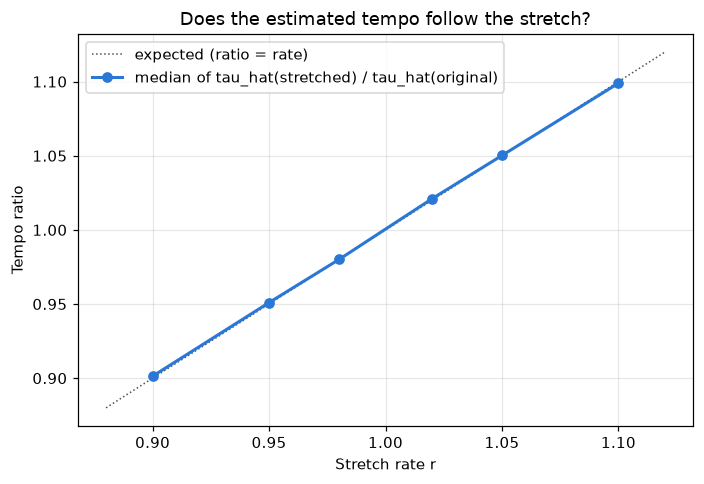

In [8]:
original_tau = data.set_index('filename')['tau_hat']
check_rows = []
for condition in CONDITIONS[1:]:
    part = conditions[conditions['condition'] == condition['condition']].set_index('filename')
    expected_ratio = condition['rate'] if condition['kind'] == 'stretch' else 1.0
    ratio = part['tau_hat']/original_tau.loc[part.index]/expected_ratio
    check_rows.append({'condition': condition['condition'], 'kind': condition['kind'], 'rate': condition['rate'],
                       'expected ratio': expected_ratio, 'median ratio': float(np.median(ratio*expected_ratio)),
                       'within 1% of expected': float(np.mean(np.abs(ratio - 1) < 0.01)),
                       'within 3%': float(np.mean(np.abs(ratio - 1) < 0.03)),
                       'octave jump': float(np.mean((np.abs(ratio - 2) < 0.1) | (np.abs(ratio - 0.5) < 0.05)))})
tempo_check = pd.DataFrame(check_rows)
save(tempo_check, 'comparison', 'tempo_check.csv', index=False)
display(tempo_check.round(3))

figure, axis = plt.subplots(figsize=(6.5, 4.5))
stretch_rows = tempo_check[tempo_check['kind'] == 'stretch']
axis.plot([0.88, 1.12], [0.88, 1.12], color='#52514e', linestyle=':', linewidth=1, label='expected (ratio = rate)')
axis.plot(stretch_rows['rate'], stretch_rows['median ratio'], marker='o', color=BLUE, linewidth=2,
          label='median of tau_hat(stretched) / tau_hat(original)')
axis.set(xlabel='Stretch rate r', ylabel='Tempo ratio', title='Does the estimated tempo follow the stretch?')
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
save_figure(figure, 'comparison', 'tempo_check.png')

## 7. SVM–RBF and its search space

The same model and search method as in the timbral notebook. The grid is wider (`C` up to 1000, `gamma` up to 1000): in the first run the tempo-only search chose the largest `C` and the largest `gamma` in all five folds, so the best setting lay outside the grid. With a single input, a useful boundary has to be very local (a few BPM wide), which needs a large `gamma`. The SVM separates the genres with boundaries that keep a wide margin; the RBF kernel $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$ allows curved boundaries. The inputs are standardized inside a **pipeline**, so the scaler learns its means and standard deviations only from the training clips of each split.

| Setting | Meaning | Values |
|---|---|---|
| `C` | Larger values penalize training errors more strongly | 0.1, 1, 10, 100, 1000 |
| `gamma` | Larger values make the similarity more local | scale, 0.001, 0.01, 0.1, 1, 10, 100, 1000 |
| `class_weight` | `balanced` gives the rarer genres more weight | None, balanced |

The default model uses `C=1`, `gamma='scale'` and equal class weights. The **grid search** tries all 80 combinations on the inner folds. `scale` means 1 / (number of inputs × input variance); after standardizing that is 1/19 for the rhythm set and exactly 1 for the tempo-only set, where `scale` and `1` are therefore the same setting.

In [9]:
base_estimator = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale')),
])
parameter_grid = {
    'svm__C': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
    'svm__class_weight': [None, 'balanced'],
}

# Ends of the grid that could still be extended (checked in section 11).
numeric_gammas = [g for g in parameter_grid['svm__gamma'] if g != 'scale']
EDGE_VALUES = {
    'svm__C': [min(parameter_grid['svm__C']), max(parameter_grid['svm__C'])],
    'svm__gamma': [min(numeric_gammas), max(numeric_gammas)],
}


def make_search(inner_cv):
    return GridSearchCV(
        estimator=base_estimator,
        param_grid=parameter_grid,
        scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
        refit='macro_f1',        # choose the settings with the best inner macro-F1
        cv=inner_cv,
        n_jobs=N_JOBS,
        error_score='raise',
    )

## 8. Evaluation measures

| Measure | Meaning |
|---|---|
| Accuracy | Share of correctly classified recordings |
| Macro precision | Average per-genre precision: how reliable each genre's predictions are |
| Macro recall = balanced accuracy | Average per-genre recall: how many recordings of each genre are found |
| Macro-F1 | Average per-genre F1, so every genre counts equally |
| Weighted F1 | Per-genre F1 weighted by the number of recordings |
| Confusion matrix | Counts of true genres (rows) against predicted genres (columns) |

Chance level is about 16% accuracy (always guessing ChaChaCha) and 12.5% balanced accuracy. All results come from the **outer test folds**; **mean ± SD** is over the five folds (the SD describes how much the folds vary, it is not a confidence interval).

In [10]:
def classification_scores(y_true, y_pred):
    def average(metric, how):
        return metric(y_true, y_pred, labels=class_labels, average=how, zero_division=0)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': average(precision_score, 'macro'),
        'macro_recall': average(recall_score, 'macro'),
        'macro_f1': average(f1_score, 'macro'),
        'weighted_f1': average(f1_score, 'weighted'),
    }


def summarize_folds(fold_metrics, metrics=METRICS, by=('variant',)):
    summary = fold_metrics.groupby(list(by), sort=False)[metrics].agg(['mean', 'std'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


def mean_sd_table(summary, metrics=METRICS, index='variant'):
    return pd.DataFrame({metric: [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
                         for metric in metrics}, index=summary[index]).T


def paired_differences(table_a, table_b, metric='macro_f1', names=('A', 'B')):
    a = table_a.set_index(['fold', 'variant'])[metric]
    b = table_b.set_index(['fold', 'variant'])[metric]
    difference = (100*(b - a)).rename(f'{names[1]} - {names[0]} (pp)').reset_index()
    return difference.pivot(index='fold', columns='variant', values=difference.columns[-1])

## 9. Train and evaluate with nested cross-validation

For each feature set and each outer fold: fit the **default** model on the 4 training folds; split those training folds into 3 grouped **inner folds** and let the grid search choose the settings with the best inner macro-F1; refit them on all 4 training folds (the **tuned** model); predict the untouched test fold with both. The test fold is never used for training or tuning.

In [11]:
@dataclass
class CVResults:
    feature_columns: list
    fold_metrics: pd.DataFrame
    predictions: pd.DataFrame
    best_parameters: pd.DataFrame
    models: dict = field(repr=False)


def run_nested_cv(data, feature_columns, verbose=True):
    fold_rows, parameter_rows, models = [], [], {}
    predictions = data[['filename', 'label', 'group_id', 'fold']].copy()
    for variant in VARIANTS:
        predictions[f'prediction_{variant.lower()}'] = ''

    for fold in sorted(data['fold'].unique()):
        train, test = data['fold'] != fold, data['fold'] == fold
        X_train, y_train = data.loc[train, feature_columns], data.loc[train, 'label']
        X_test, y_test = data.loc[test, feature_columns], data.loc[test, 'label']
        assert not set(data.loc[train, 'group_id']) & set(data.loc[test, 'group_id'])

        default = clone(base_estimator).fit(X_train, y_train)
        inner_cv = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_SEED + fold)
        search = make_search(inner_cv)
        start = time.perf_counter()
        search.fit(X_train, y_train, groups=data.loc[train, 'group_id'])
        tuning_seconds = time.perf_counter() - start
        tuned = search.best_estimator_

        models[fold] = {'Default': default, 'Tuned': tuned}
        for variant, model in [('Default', default), ('Tuned', tuned)]:
            predicted = model.predict(X_test)
            predictions.loc[test, f'prediction_{variant.lower()}'] = predicted
            fold_rows.append({'fold': fold, 'variant': variant, **classification_scores(y_test, predicted),
                              'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
                              'oob_accuracy': getattr(model, 'oob_score_', np.nan)})
        chosen = {name: ('None' if value is None else value) for name, value in search.best_params_.items()}
        parameter_rows.append({'fold': fold, 'inner_best_macro_f1': search.best_score_, **chosen})
        if verbose:
            d, t = fold_rows[-2], fold_rows[-1]
            print(f'  fold {fold}: accuracy default {d["accuracy"]:.3f} / tuned {t["accuracy"]:.3f}, '
                  f'macro-F1 default {d["macro_f1"]:.3f} / tuned {t["macro_f1"]:.3f} (tuning {tuning_seconds:.1f} s)',
                  flush=True)

    for variant in VARIANTS:
        assert (predictions[f'prediction_{variant.lower()}'] != '').all(), 'a clip was never tested'
    return CVResults(feature_columns, pd.DataFrame(fold_rows), predictions, pd.DataFrame(parameter_rows), models)


cv = {}
for set_name, columns in FEATURE_SETS.items():
    print(f'{set_name} ({len(columns)} inputs)')
    cv[set_name] = run_nested_cv(data, columns)
    save(cv[set_name].fold_metrics, set_name, 'fold_metrics.csv', index=False)
    save(cv[set_name].predictions, set_name, 'out_of_fold_predictions.csv', index=False)
    save(cv[set_name].best_parameters, set_name, 'best_parameters.csv', index=False)

Rhythm (20 inputs)


  fold 1: accuracy default 0.843 / tuned 0.850, macro-F1 default 0.839 / tuned 0.844 (tuning 4.3 s)


  fold 2: accuracy default 0.771 / tuned 0.793, macro-F1 default 0.760 / tuned 0.782 (tuning 1.2 s)


  fold 3: accuracy default 0.843 / tuned 0.864, macro-F1 default 0.836 / tuned 0.861 (tuning 1.2 s)


  fold 4: accuracy default 0.784 / tuned 0.820, macro-F1 default 0.785 / tuned 0.818 (tuning 1.0 s)


...

  fold 1: accuracy default 0.593 / tuned 0.643, macro-F1 default 0.489 / tuned 0.617 (tuning 0.9 s)


  fold 2: accuracy default 0.593 / tuned 0.629, macro-F1 default 0.504 / tuned 0.614 (tuning 1.0 s)


  fold 3: accuracy default 0.607 / tuned 0.700, macro-F1 default 0.522 / tuned 0.681 (tuning 0.8 s)


  fold 4: accuracy default 0.561 / tuned 0.676, macro-F1 default 0.492 / tuned 0.667 (tuning 0.8 s)


  fold 5: accuracy default 0.540 / tuned 0.669, macro-F1 default 0.464 / tuned 0.654 (tuning 0.8 s)


## 10. Results on the original recordings

In [12]:
summaries = {}
for set_name, result in cv.items():
    summaries[set_name] = summarize_folds(result.fold_metrics)
    save(summaries[set_name], set_name, 'metric_summary.csv', index=False)

both = pd.concat([s.assign(label=f'{name}, ' + s['variant']) for name, s in summaries.items()])
print('Five outer test folds, mean ± SD (%)')
display(mean_sd_table(both, index='label'))

for set_name, result in cv.items():
    tuning = result.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')
    print(f'{set_name}: mean macro-F1 change from tuning '
          f'{100*(tuning["Tuned"] - tuning["Default"]).mean():+.2f} percentage points')

Five outer test folds, mean ± SD (%)


label,"Rhythm, Default","Rhythm, Tuned","Tempo only, Default","Tempo only, Tuned"
accuracy,81.95 ± 3.87,83.09 ± 2.76,57.87 ± 2.76,66.34 ± 2.82
balanced_accuracy,81.37 ± 4.28,82.69 ± 3.15,55.57 ± 2.71,65.58 ± 3.49
macro_precision,82.62 ± 4.11,83.64 ± 3.28,59.05 ± 2.36,70.95 ± 2.97
macro_recall,81.37 ± 4.28,82.69 ± 3.15,55.57 ± 2.71,65.58 ± 3.49
macro_f1,81.54 ± 4.09,82.66 ± 3.01,49.41 ± 2.13,64.66 ± 3.00
weighted_f1,81.85 ± 3.68,82.86 ± 2.70,51.93 ± 2.26,64.95 ± 2.80


Rhythm: mean macro-F1 change from tuning +1.12 percentage points
Tempo only: mean macro-F1 change from tuning +15.25 percentage points


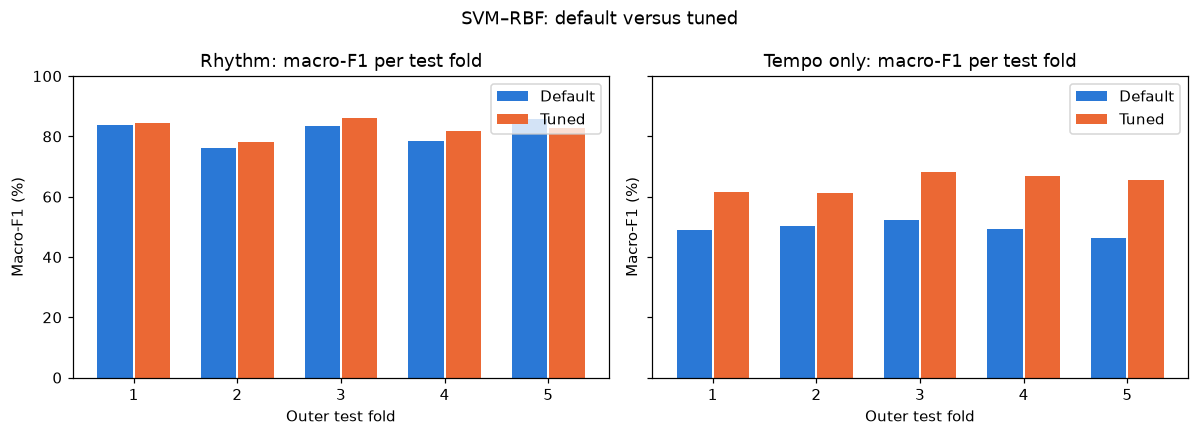

In [13]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, (set_name, result) in zip(axes, cv.items()):
    table = result.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')[VARIANTS]
    positions = np.arange(len(table))
    for k, (variant, color) in enumerate(zip(VARIANTS, [BLUE, ORANGE])):
        axis.bar(positions + (k - 0.5)*0.36, 100*table[variant], width=0.34, color=color, label=variant)
    axis.set_xticks(positions, table.index)
    axis.set(title=f'{set_name}: macro-F1 per test fold', xlabel='Outer test fold', ylabel='Macro-F1 (%)', ylim=(0, 100))
    axis.legend(loc='upper right')
figure.suptitle(f'{MODEL_NAME}: default versus tuned')
figure.tight_layout()
save_figure(figure, 'comparison', 'fold_performance.png')

## 11. Chosen settings and overfitting check

`inner_best_macro_f1` is the tuning score on the inner folds, not a final result. For the SVM the gap between training accuracy and test accuracy is a useful check: a large `C` together with a large `gamma` lets the SVM fit almost every training clip, which shows up as a training accuracy near 100% with a much lower test accuracy.

The last line counts the folds whose chosen value is at an end of the grid. If most folds choose an end, the best setting may lie outside the grid, and the grid should be widened before the results are reported.

In [14]:
# How many folds chose a value at an end of the grid (EDGE_VALUES, section 7). If most folds
# do, the best setting may lie outside the grid and the grid should be wider.
def count_edge_choices(best_parameters):
    return {name: int(best_parameters[name].isin(ends).sum()) for name, ends in EDGE_VALUES.items()}


for set_name, result in cv.items():
    print(set_name)
    display(result.best_parameters.round(4))
    display(result.fold_metrics[['fold', 'variant', 'train_accuracy', 'accuracy', 'macro_f1']].round(4))
    edge_counts = count_edge_choices(result.best_parameters)
    print(f'folds (of {len(result.best_parameters)}) that chose an end of the grid: {edge_counts}')

Rhythm


,fold,inner_best_macro_f1,svm__C,svm__class_weight,svm__gamma
0,1,0.8276,10.0,None,0.01
1,2,0.8161,10.0,None,0.01
2,3,0.8324,100.0,None,0.001
3,4,0.8137,100.0,None,0.001
4,5,0.8159,10.0,balanced,scale


,fold,variant,train_accuracy,accuracy,macro_f1
0,1,Default,0.9122,0.8429,0.8386
1,1,Tuned,0.9140,0.8500,0.8443
2,2,Default,0.9104,0.7714,0.7604
3,2,Tuned,0.9229,0.7929,0.7816
4,3,Default,0.9140,0.8429,0.8357
5,3,Tuned,0.8996,0.8643,0.8613
6,4,Default,0.9177,0.7842,0.7848
7,4,Tuned,0.8962,0.8201,0.8177
8,5,Default,0.9159,0.8561,0.8575
9,5,Tuned,0.9875,0.8273,0.8282


folds (of 5) that chose an end of the grid: {'svm__C': 0, 'svm__gamma': 2}
Tempo only


,fold,inner_best_macro_f1,svm__C,svm__class_weight,svm__gamma
0,1,0.6643,1.0,None,1000.0
1,2,0.6488,1.0,None,1000.0
2,3,0.6238,1.0,None,1000.0
3,4,0.6329,1.0,None,1000.0
4,5,0.6540,1.0,None,1000.0


,fold,variant,train_accuracy,accuracy,macro_f1
0,1,Default,0.5860,0.5929,0.4892
1,1,Tuned,0.7168,0.6429,0.6169
2,2,Default,0.5681,0.5929,0.5039
3,2,Tuned,0.7186,0.6286,0.6137
4,3,Default,0.5735,0.6071,0.5219
5,3,Tuned,0.7043,0.7000,0.6806
6,4,Default,0.5957,0.5612,0.4915
7,4,Tuned,0.7138,0.6763,0.6675
8,5,Default,0.5832,0.5396,0.4639
9,5,Tuned,0.7138,0.6691,0.6543


folds (of 5) that chose an end of the grid: {'svm__C': 0, 'svm__gamma': 5}


## 12. Confusion matrices, per-genre results and common errors

Rows are the **true genres** and columns the **predicted genres**; every row is divided by the number of recordings of that genre, so the diagonal is the recall of each genre. Compare the two feature sets: the tempo-only model can only separate genres whose tempo ranges differ, so its errors show which genres share a tempo.

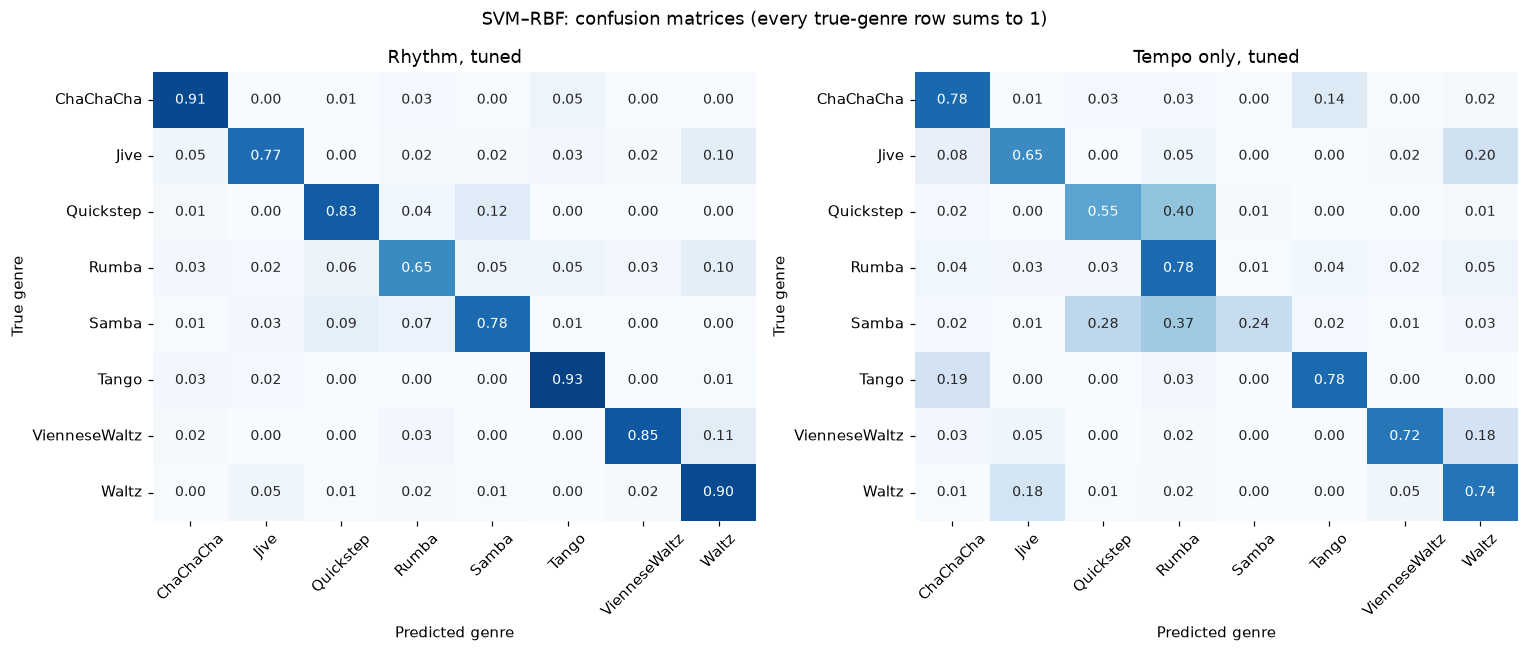

Rhythm, tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.8938,0.9099,0.9018,111
Jive,0.7931,0.7667,0.7797,60
Quickstep,0.8095,0.8293,0.8193,82
Rumba,0.7901,0.6531,0.7151,98
Samba,0.7976,0.7791,0.7882,86
Tango,0.8511,0.9302,0.8889,86
VienneseWaltz,0.9016,0.8462,0.8730,65
Waltz,0.8049,0.9000,0.8498,110


Tempo only, tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.7311,0.7838,0.7565,111
Jive,0.5821,0.6500,0.6142,60
Quickstep,0.5921,0.5488,0.5696,82
Rumba,0.4967,0.7755,0.6056,98
Samba,0.9130,0.2442,0.3853,86
Tango,0.7614,0.7791,0.7701,86
VienneseWaltz,0.8393,0.7231,0.7769,65
Waltz,0.6983,0.7364,0.7168,110


In [15]:
def confusion_tables(y_true, y_pred):
    counts = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=class_labels), index=class_labels, columns=class_labels)
    return counts, counts.div(counts.sum(axis=1), axis=0)


def plot_confusions(tables, titles, suptitle, ncols=2):
    nrows = int(np.ceil(len(tables)/ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 6*nrows), squeeze=False)
    for axis in axes.flat[len(tables):]:
        axis.set_visible(False)
    for axis, table, title in zip(axes.flat, tables, titles):
        sns.heatmap(table, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axis, vmin=0, vmax=1, annot_kws={'size': 9})
        axis.set(title=title, xlabel='Predicted genre', ylabel='True genre')
        axis.tick_params(axis='x', rotation=45)
        axis.tick_params(axis='y', rotation=0)
    figure.suptitle(suptitle)
    figure.tight_layout()
    return figure


def per_genre_report(y_true, y_pred):
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=class_labels,
                                                output_dict=True, zero_division=0)).T.loc[class_labels]
    report['support'] = report['support'].astype(int)
    return report


tables, titles = [], []
for set_name, result in cv.items():
    for variant in VARIANTS:
        counts, normalized = confusion_tables(result.predictions['label'], result.predictions[f'prediction_{variant.lower()}'])
        save(counts, set_name, f'confusion_counts_{variant.lower()}.csv')
        save(normalized, set_name, f'confusion_normalized_{variant.lower()}.csv')
        if variant == 'Tuned':
            tables.append(normalized)
            titles.append(f'{set_name}, tuned')
save_figure(plot_confusions(tables, titles, f'{MODEL_NAME}: confusion matrices (every true-genre row sums to 1)'),
            'comparison', 'confusion_normalized_tuned.png')

for set_name, result in cv.items():
    report = per_genre_report(result.predictions['label'], result.predictions['prediction_tuned'])
    save(report, set_name, 'per_genre_report_tuned.csv', index_label='genre')
    print(f'{set_name}, tuned: per-genre precision, recall and F1')
    display(report.round(4))

## 13. Which rhythm feature families does the tuned model use?

**Group permutation importance** for the rhythm set: we shuffle all columns of one family together across the test clips of a fold and measure how much macro-F1 drops (5 repeats per family and fold). A big drop means the model relies on that family. The families have different sizes (15, 3 and 2 inputs) and can be correlated, so this is for interpretation only. If the cyclic tempogram matters most, the model relies on the tempo class, which the time-stretch sections test directly.

,mean macro-F1 drop (pp),SD over folds (pp)
feature_family,,
Cyclic tempogram,64.24,2.53
PLP,18.62,3.93
Bar ratios,3.50,2.66


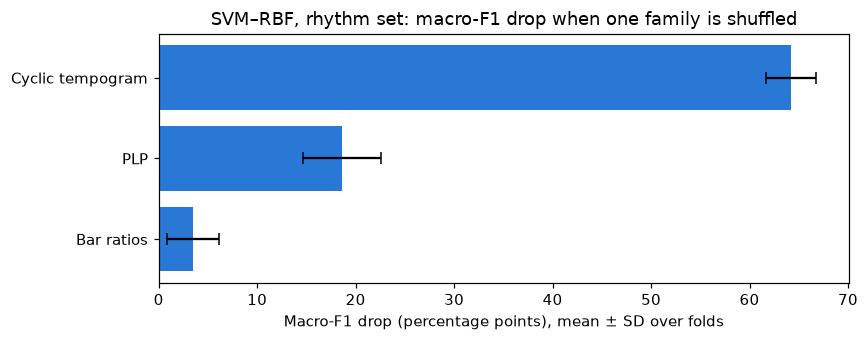

In [16]:
result = cv['Rhythm']
rows = []
for fold, fold_models in result.models.items():
    test = data['fold'] == fold
    X_test, y_test = data.loc[test, RHYTHM_COLUMNS], data.loc[test, 'label']
    model = fold_models['Tuned']
    baseline = f1_score(y_test, model.predict(X_test), average='macro', zero_division=0)
    for family, columns in FEATURE_GROUPS.items():
        for repeat in range(IMPORTANCE_REPEATS):
            order = np.random.default_rng(RANDOM_SEED + 100*fold + repeat).permutation(len(X_test))
            shuffled = X_test.copy()
            shuffled[columns] = X_test[columns].to_numpy()[order]
            score = f1_score(y_test, model.predict(shuffled), average='macro', zero_division=0)
            rows.append({'fold': fold, 'feature_family': family, 'macro_f1_drop': baseline - score})
per_fold = pd.DataFrame(rows).groupby(['fold', 'feature_family'])['macro_f1_drop'].mean()
importance = per_fold.groupby('feature_family').agg(['mean', 'std']).sort_values('mean', ascending=False)
save(importance, 'Rhythm', 'feature_family_importance.csv')
display((100*importance).rename(columns={'mean': 'mean macro-F1 drop (pp)', 'std': 'SD over folds (pp)'}).round(2))

figure, axis = plt.subplots(figsize=(8, 3.2))
positions = np.arange(len(importance))
axis.barh(positions, 100*importance['mean'], xerr=100*importance['std'], color=BLUE, capsize=4)
axis.set_yticks(positions, importance.index)
axis.invert_yaxis()
axis.axvline(0, color='#52514e', linewidth=1)
axis.set(title=f'{MODEL_NAME}, rhythm set: macro-F1 drop when one family is shuffled',
         xlabel='Macro-F1 drop (percentage points), mean ± SD over folds')
figure.tight_layout()
save_figure(figure, 'Rhythm', 'feature_family_importance.png')

## 14. Compare the two classifiers

Both rhythm notebooks use the same folds, so the comparison is **paired**: for every fold we subtract the other model's macro-F1. This cell needs `Rhythm_Random_Forest.ipynb` to have run; if it hasn't, run it and then rerun this cell.

In [17]:
for set_name in FEATURE_SETS:
    other_path = OTHER_RESULTS_DIR / SET_DIRS[set_name] / 'fold_metrics.csv'
    if not other_path.is_file():
        print(f'{set_name}: run the {OTHER_MODEL_NAME} notebook, then rerun this cell.')
        continue
    other = pd.read_csv(other_path)
    pair = pd.concat([summarize_folds(cv[set_name].fold_metrics, ['accuracy', 'macro_f1']).assign(model=MODEL_NAME),
                      summarize_folds(other, ['accuracy', 'macro_f1']).assign(model=OTHER_MODEL_NAME)])
    pair['label'] = pair['model'] + ', ' + pair['variant']
    print(f'{set_name}: same recordings and folds, mean ± SD (%)')
    display(mean_sd_table(pair, ['accuracy', 'macro_f1'], index='label'))
    print(f'{set_name}: per fold, macro-F1 of {MODEL_NAME} minus {OTHER_MODEL_NAME} (percentage points)')
    display(paired_differences(other, cv[set_name].fold_metrics, names=(OTHER_MODEL_NAME, MODEL_NAME)).round(2))

Rhythm: same recordings and folds, mean ± SD (%)


label,"SVM–RBF, Default","SVM–RBF, Tuned","Random Forest, Default","Random Forest, Tuned"
accuracy,81.95 ± 3.87,83.09 ± 2.76,82.23 ± 1.67,82.38 ± 2.74
macro_f1,81.54 ± 4.09,82.66 ± 3.01,81.97 ± 1.69,81.91 ± 3.06


Rhythm: per fold, macro-F1 of SVM–RBF minus Random Forest (percentage points)


variant,Default,Tuned
fold,,
1,-0.88,0.21
2,-4.36,1.44
3,1.41,2.75
4,-3.18,0.18
5,4.86,-0.84


Tempo only: same recordings and folds, mean ± SD (%)


label,"SVM–RBF, Default","SVM–RBF, Tuned","Random Forest, Default","Random Forest, Tuned"
accuracy,57.87 ± 2.76,66.34 ± 2.82,57.59 ± 5.05,63.60 ± 3.53
macro_f1,49.41 ± 2.13,64.66 ± 3.00,56.55 ± 4.87,62.59 ± 2.99


Tempo only: per fold, macro-F1 of SVM–RBF minus Random Forest (percentage points)


variant,Default,Tuned
fold,,
1,-5.87,-0.29
2,-0.58,-1.99
3,-12.09,1.10
4,-6.51,4.81
5,-10.67,6.75


---
# TIME-STRETCH EXPERIMENT STARTS HERE

## 15. What to expect

The fold models from section 9 are used as they are: trained and tuned on the original audio only, never refitted. Only `.predict()` is called on the features of the changed audio, and every version keeps its genre label and test fold. The **paired baseline** is the prediction on the original features, so the flip rate (share of clips whose prediction changes) and the metric changes compare the same clips with the same model.

* **Tempo only:** if the model works mainly through tempo, it should get worse as the stretch grows, and the round trip (tempo unchanged) should hardly change it.
* **Rhythm:** the bar ratios are measured in beats, so they depend on the tempo only through the tempo estimate; the cyclic tempogram is not shifted, so it moves with the tempo (a 10% stretch moves it by about 2 of its 15 bins). If the rhythm model drops like the tempo-only model, it is using the tempo shortcut.
* **Round trip:** a drop here comes from the processing, not from the tempo. Only the part of a stretch drop that the round trip does not show can be blamed on the tempo.

In [18]:
def evaluate_conditions(result, columns):
    by_condition = {name: rows.set_index('filename') for name, rows in conditions.groupby('condition')}
    metric_rows, prediction_rows = [], []
    for fold, fold_models in result.models.items():
        test_files = data.loc[data['fold'] == fold, 'filename']
        y_test = data.loc[data['fold'] == fold, 'label'].to_numpy()
        for variant, model in fold_models.items():
            baseline = model.predict(by_condition['original'].loc[test_files, columns])
            baseline_scores = classification_scores(y_test, baseline)
            for condition in CONDITIONS:
                predicted = model.predict(by_condition[condition['condition']].loc[test_files, columns])
                scores = classification_scores(y_test, predicted)
                metric_rows.append({'fold': fold, 'variant': variant, **condition, **scores,
                                    'flip_rate': np.mean(predicted != baseline),
                                    'accuracy_change_pp': 100*(scores['accuracy'] - baseline_scores['accuracy']),
                                    'macro_f1_change_pp': 100*(scores['macro_f1'] - baseline_scores['macro_f1'])})
                prediction_rows.append(pd.DataFrame({'filename': test_files.to_numpy(), 'label': y_test, 'fold': fold,
                                                     'variant': variant, 'condition': condition['condition'],
                                                     'prediction': predicted, 'baseline_prediction': baseline}))
    return pd.DataFrame(metric_rows), pd.concat(prediction_rows, ignore_index=True)


condition_metrics, condition_predictions, stretch_summary = {}, {}, {}
for set_name, columns in FEATURE_SETS.items():
    condition_metrics[set_name], condition_predictions[set_name] = evaluate_conditions(cv[set_name], columns)
    stretch_summary[set_name] = summarize_folds(
        condition_metrics[set_name], ['accuracy', 'macro_f1', 'flip_rate', 'accuracy_change_pp', 'macro_f1_change_pp'],
        by=('variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
    folder = RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch'
    condition_metrics[set_name].to_csv(folder / 'fold_metrics.csv', index=False)
    condition_predictions[set_name].to_csv(folder / 'held_out_predictions.csv', index=False)
    stretch_summary[set_name].to_csv(folder / 'robustness_summary.csv', index=False)
print('evaluated', ', '.join(FEATURE_SETS), 'on all', len(CONDITIONS), 'versions')

evaluated Rhythm, Tempo only on all 13 versions


## 16. Results per condition

Mean ± SD over the five test folds. The change compares each version with the original audio **within the same fold**; negative values mean lower performance. Do not choose hyperparameters from these numbers: they are test results.

In [19]:
for set_name, summary in stretch_summary.items():
    table = summary[['variant', 'condition', 'tempo_change_percent']].copy()
    for metric in ['accuracy', 'macro_f1', 'flip_rate']:
        table[f'{metric} (%)'] = [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
    table['macro-F1 change (pp)'] = summary['macro_f1_change_pp_mean'].round(2)
    print(set_name)
    display(table.reset_index(drop=True))

Rhythm


,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),macro-F1 change (pp)
0,Default,original,0.0,81.95 ± 3.87,81.54 ± 4.09,0.00 ± 0.00,0.00
1,Default,stretch_0.90,-10.0,32.22 ± 9.62,26.81 ± 8.61,64.92 ± 8.58,-54.73
2,Default,stretch_0.95,-5.0,47.85 ± 2.36,41.77 ± 2.60,47.14 ± 5.04,-39.77
3,Default,stretch_0.98,-2.0,66.90 ± 3.47,65.22 ± 3.35,25.51 ± 4.97,-16.32
4,Default,stretch_1.02,2.0,68.48 ± 4.37,67.59 ± 4.64,28.22 ± 3.35,-13.95
5,Default,stretch_1.05,5.0,38.40 ± 4.67,37.47 ± 4.85,57.87 ± 5.06,-44.07
6,Default,stretch_1.10,10.0,12.61 ± 2.53,11.54 ± 2.96,87.25 ± 2.53,-70.00
7,Default,roundtrip_0.90,0.0,74.35 ± 2.45,72.70 ± 3.17,15.47 ± 2.62,-8.84
8,Default,roundtrip_0.95,0.0,73.78 ± 1.85,72.28 ± 2.49,15.90 ± 1.82,-9.26
9,Default,roundtrip_0.98,0.0,73.78 ± 2.11,72.20 ± 2.58,16.62 ± 1.90,-9.34


Tempo only


,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),macro-F1 change (pp)
0,Default,original,0.0,57.87 ± 2.76,49.41 ± 2.13,0.00 ± 0.00,0.00
1,Default,stretch_0.90,-10.0,16.19 ± 1.35,10.46 ± 2.63,77.65 ± 2.39,-38.95
2,Default,stretch_0.95,-5.0,34.37 ± 3.91,24.01 ± 3.48,50.70 ± 5.01,-25.39
3,Default,stretch_0.98,-2.0,48.42 ± 4.12,38.58 ± 4.79,25.05 ± 6.84,-10.83
4,Default,stretch_1.02,2.0,53.14 ± 2.41,44.41 ± 2.53,17.06 ± 2.70,-5.00
5,Default,stretch_1.05,5.0,41.55 ± 2.26,34.31 ± 1.77,35.96 ± 3.07,-15.10
6,Default,stretch_1.10,10.0,25.51 ± 3.33,20.13 ± 2.33,64.60 ± 6.11,-29.28
7,Default,roundtrip_0.90,0.0,55.58 ± 1.89,47.15 ± 1.74,7.02 ± 2.15,-2.26
8,Default,roundtrip_0.95,0.0,55.72 ± 2.32,47.13 ± 1.96,6.59 ± 2.10,-2.28
9,Default,roundtrip_0.98,0.0,56.16 ± 1.44,47.52 ± 0.89,6.30 ± 1.97,-1.89


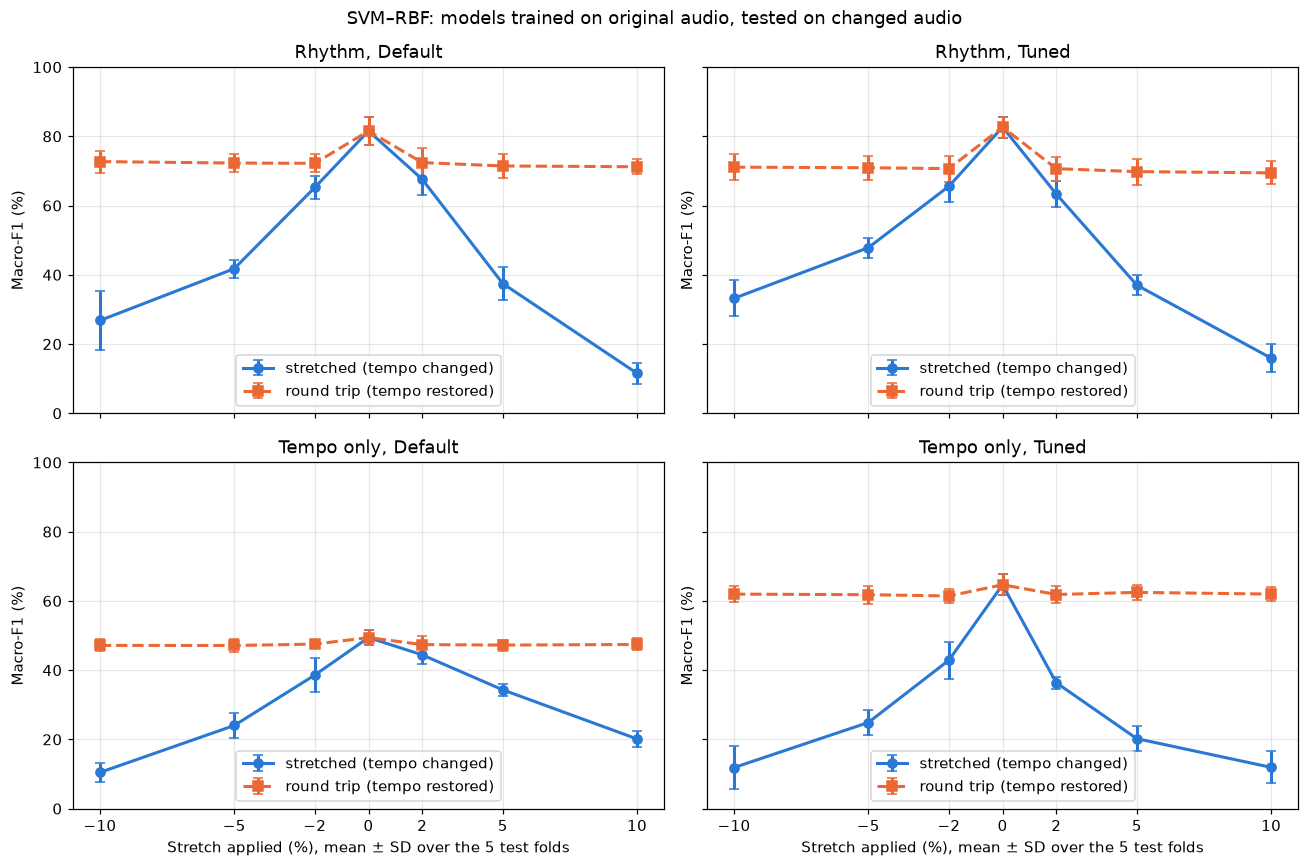

In [20]:
LINES = [('stretch', BLUE, '-', 'o', 'stretched (tempo changed)'),
         ('roundtrip', ORANGE, '--', 's', 'round trip (tempo restored)')]

figure, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for row, (set_name, summary) in enumerate(stretch_summary.items()):
    for col, variant in enumerate(VARIANTS):
        axis = axes[row, col]
        rows = summary[summary['variant'] == variant]
        for kind, color, style, marker, legend in LINES:
            part = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
            axis.errorbar(100*(part['rate'] - 1), 100*part['macro_f1_mean'], yerr=100*part['macro_f1_std'],
                          color=color, linestyle=style, marker=marker, markersize=6, linewidth=2, capsize=3, label=legend)
        axis.set(ylim=(0, 100), ylabel='Macro-F1 (%)', title=f'{set_name}, {variant}')
        axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend(loc='lower center')
for axis in axes[1]:
    axis.set_xlabel('Stretch applied (%), mean ± SD over the 5 test folds')
figure.suptitle(f'{MODEL_NAME}: models trained on original audio, tested on changed audio')
figure.tight_layout()
save_figure(figure, 'comparison', 'robustness_curves.png')

## 17. Confusion matrices and per-genre changes (tuned models)

For each feature set: the row-normalised confusion matrices at −10% and +10% tempo, and the change of every genre's F1 for all stretches and round trips (blue = better, red = worse). If faster or slower audio pushes clips towards the genre whose tempo range they move into, it shows up here.

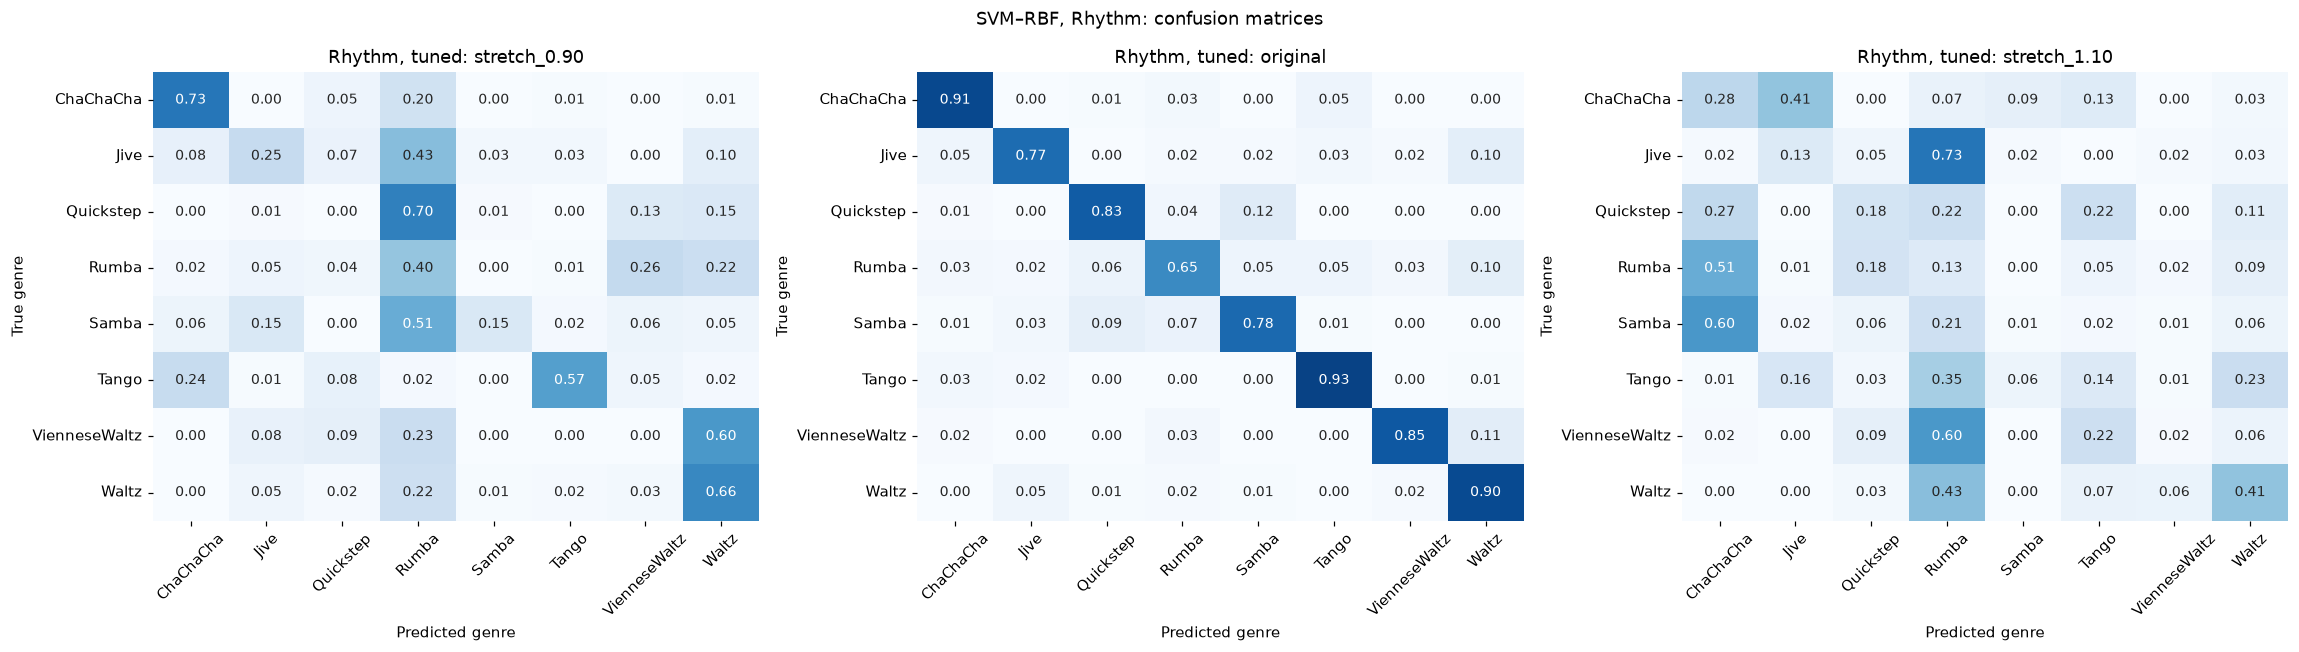

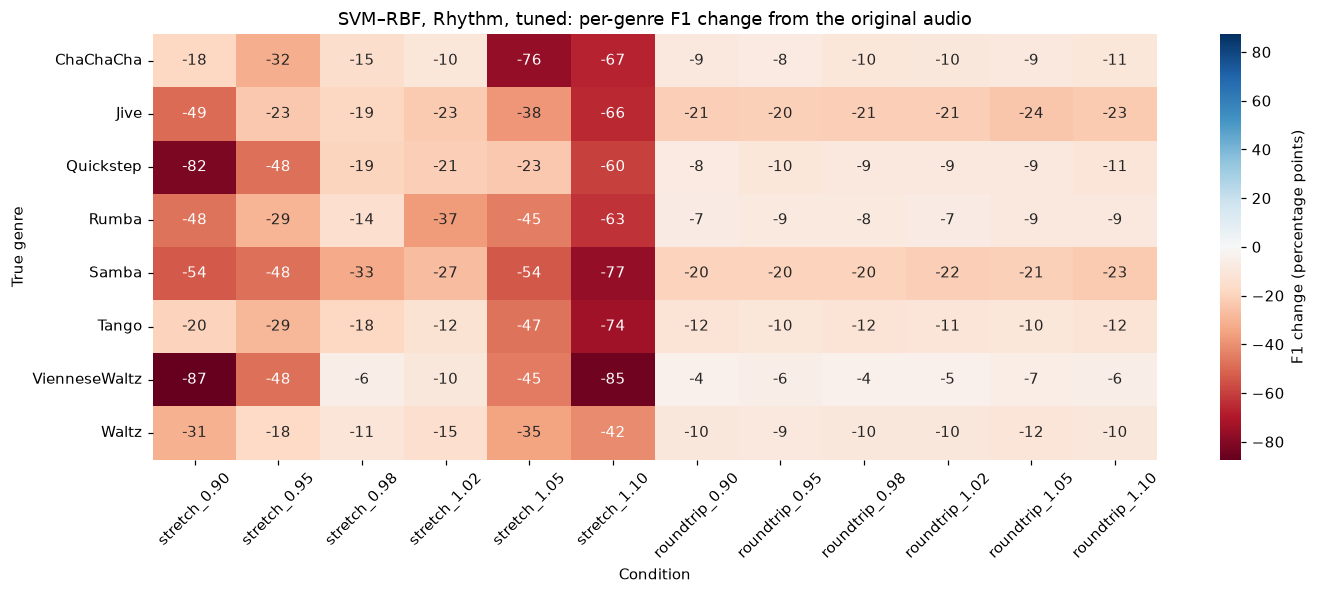

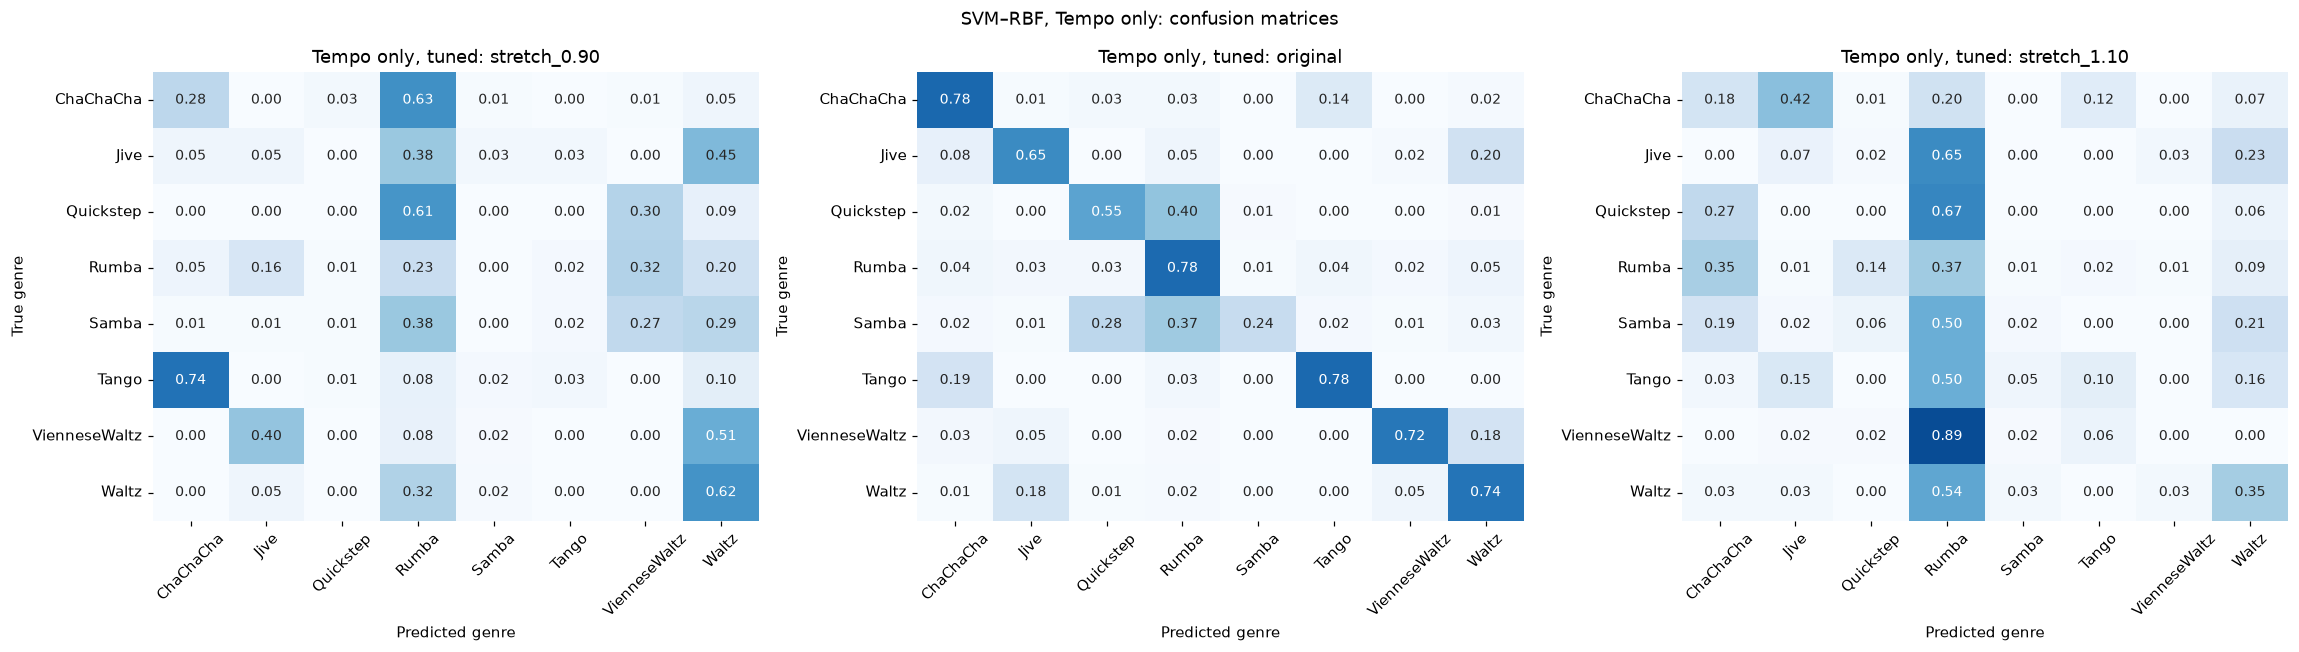

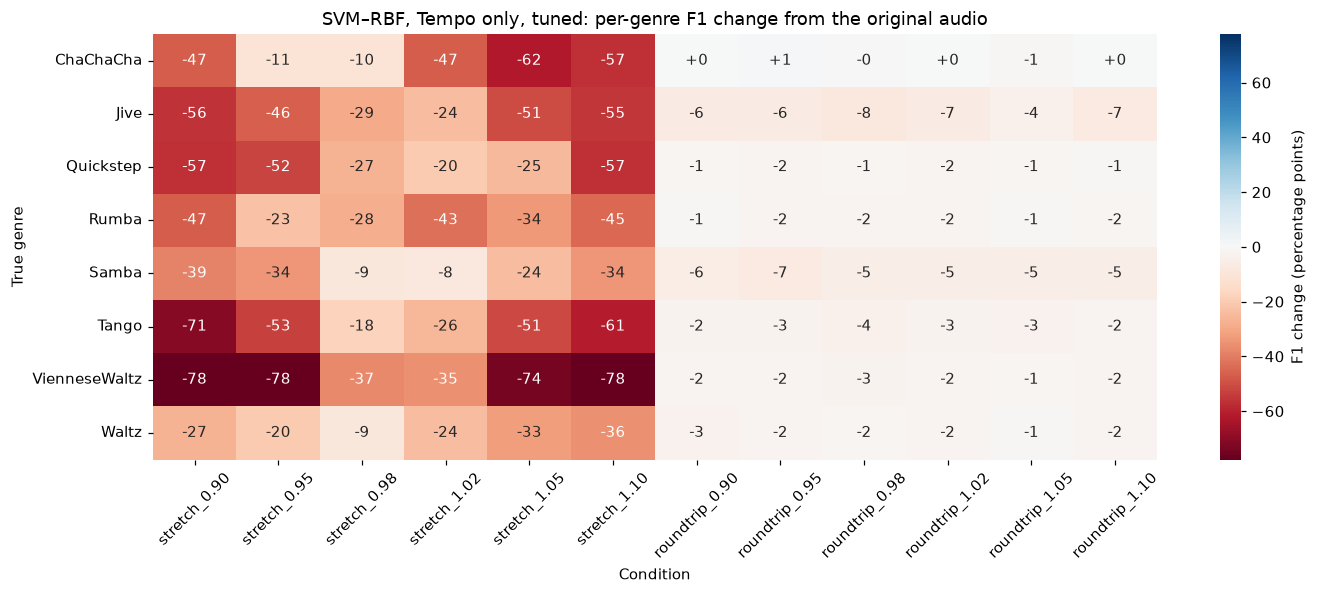

In [21]:
for set_name in FEATURE_SETS:
    tuned = condition_predictions[set_name][condition_predictions[set_name]['variant'] == 'Tuned']
    tables, titles = [], []
    for name in ['stretch_0.90', 'original', 'stretch_1.10']:
        rows = tuned[tuned['condition'] == name]
        tables.append(confusion_tables(rows['label'], rows['prediction'])[1])
        titles.append(f'{set_name}, tuned: {name}')
    save_figure(plot_confusions(tables, titles, f'{MODEL_NAME}, {set_name}: confusion matrices', ncols=3),
                set_name, 'time_stretch/confusion_normalized.png')

    f1_by_condition = pd.DataFrame({name: per_genre_report(rows['label'], rows['prediction'])['f1-score']
                                    for name, rows in tuned.groupby('condition')})[CONDITION_ORDER]
    f1_by_condition.to_csv(RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch' / 'per_genre_f1_tuned.csv')
    changes = 100*f1_by_condition[CONDITION_ORDER[1:]].sub(f1_by_condition['original'], axis=0)
    bound = max(1.0, float(np.abs(changes.to_numpy()).max()))
    figure, axis = plt.subplots(figsize=(13, 5.5))
    sns.heatmap(changes, annot=True, fmt='+.0f', cmap='RdBu', center=0, vmin=-bound, vmax=bound, ax=axis,
                cbar_kws={'label': 'F1 change (percentage points)'})
    axis.set(title=f'{MODEL_NAME}, {set_name}, tuned: per-genre F1 change from the original audio',
             xlabel='Condition', ylabel='True genre')
    axis.tick_params(axis='x', rotation=45)
    axis.tick_params(axis='y', rotation=0)
    figure.tight_layout()
    save_figure(figure, set_name, 'time_stretch/per_genre_f1_change.png')

## 18. Both classifiers on the same changed audio

Needs the time-stretch sections of `Rhythm_Random_Forest.ipynb`. Each model keeps the same colour.

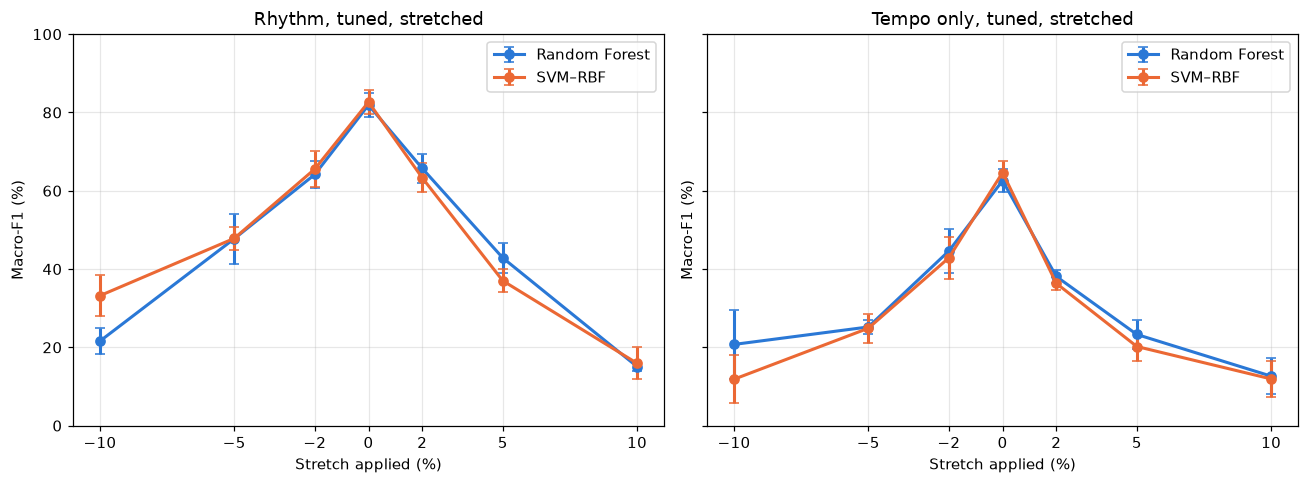

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
missing = []
for axis, set_name in zip(axes, FEATURE_SETS):
    other_path = OTHER_RESULTS_DIR / SET_DIRS[set_name] / 'time_stretch' / 'robustness_summary.csv'
    if not other_path.is_file():
        missing.append(set_name)
        continue
    combined = pd.concat([stretch_summary[set_name].assign(model=MODEL_NAME), pd.read_csv(other_path).assign(model=OTHER_MODEL_NAME)])
    for model, rows in combined[combined['variant'] == 'Tuned'].groupby('model'):
        rows = rows[rows['kind'].isin(['stretch', 'original'])].sort_values('rate')
        axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'], marker='o',
                      capsize=3, linewidth=2, label=model, color=MODEL_COLORS[model])
    axis.set(title=f'{set_name}, tuned, stretched', xlabel='Stretch applied (%)', ylabel='Macro-F1 (%)', ylim=(0, 100))
    axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
    axis.grid(alpha=0.3)
    axis.legend()
if missing:
    plt.close(figure)
    print(f'Run the time-stretch sections of the {OTHER_MODEL_NAME} notebook, then rerun this cell.')
else:
    figure.tight_layout()
    save_figure(figure, 'comparison', 'model_comparison.png')

## 19. The main result: timbral vs rhythm vs tempo-only

This answers the question of the README: **does the classifier learn the style, or does it use the tempo as a shortcut?** All three feature sets use the same model, folds, tuning and audio versions. The timbral results come from the timbral notebook of the same model (`results/svm_rbf/`); if they are missing, only the two rhythm sets are drawn.

How to read it: a feature set that relies on tempo gets worse as the stretch grows (left panel) while the round trip hardly hurts it (right panel). A feature set that describes the style stays flat in both.

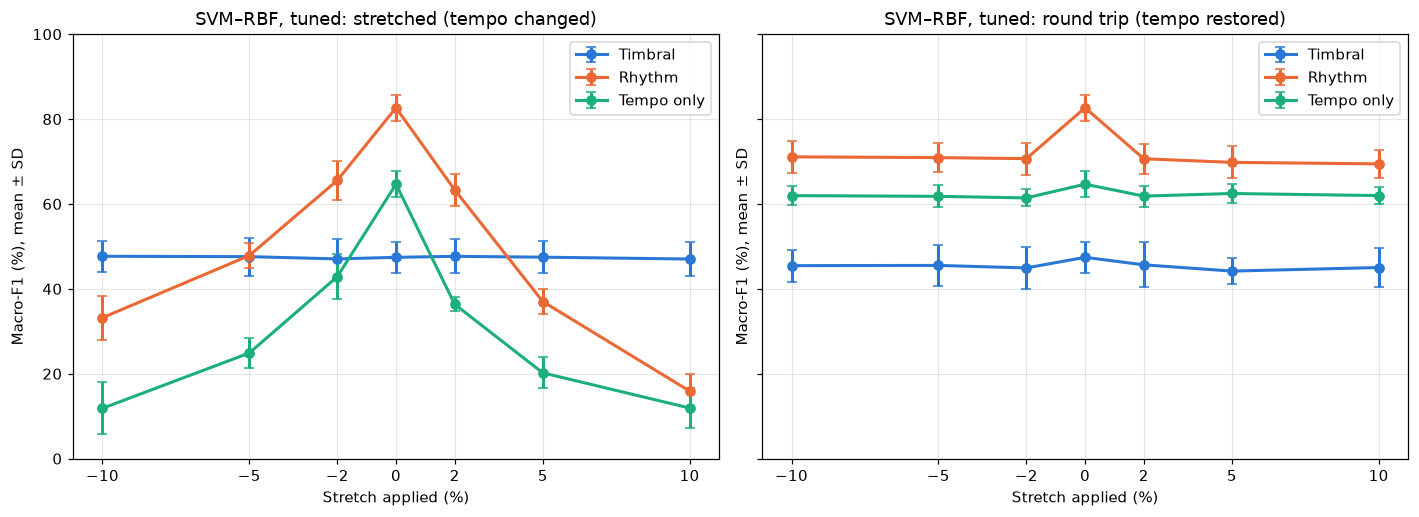

,original macro-F1 (%),"mean change, stretch (pp)","mean change, round trip (pp)",change at -10% (pp),change at +10% (pp),"mean flip rate, stretch (%)"
feature set,,,,,,
Timbral,47.43,-0.01,-2.29,0.25,-0.40,14.16
Rhythm,82.66,-38.86,-12.23,-49.46,-66.73,51.63
Tempo only,64.66,-39.98,-2.75,-52.80,-52.73,66.81


In [23]:
curves = {name: summary for name, summary in stretch_summary.items()}
timbral_path = TIMBRAL_RESULTS_DIR / 'time_stretch' / 'robustness_summary.csv'
if timbral_path.is_file():
    curves = {'Timbral': pd.read_csv(timbral_path), **curves}
else:
    print(f'{timbral_path} not found: run the timbral notebook of the same model to add it.')

figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for axis, kind, title in zip(axes, ['stretch', 'roundtrip'], ['stretched (tempo changed)', 'round trip (tempo restored)']):
    for set_name, summary in curves.items():
        rows = summary[(summary['variant'] == 'Tuned') & summary['kind'].isin([kind, 'original'])].sort_values('rate')
        axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'], marker='o',
                      capsize=3, linewidth=2, color=SET_COLORS[set_name], label=set_name)
    axis.set(title=f'{MODEL_NAME}, tuned: {title}', xlabel='Stretch applied (%)', ylabel='Macro-F1 (%), mean ± SD',
             ylim=(0, 100))
    axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
    axis.grid(alpha=0.3)
    axis.legend()
figure.tight_layout()
save_figure(figure, 'comparison', 'feature_set_comparison.png')

rows = []
for set_name, summary in curves.items():
    tuned = summary[summary['variant'] == 'Tuned'].set_index('condition')
    rows.append({'feature set': set_name,
                 'original macro-F1 (%)': 100*tuned.loc['original', 'macro_f1_mean'],
                 'mean change, stretch (pp)': tuned.loc[tuned['kind'] == 'stretch', 'macro_f1_change_pp_mean'].mean(),
                 'mean change, round trip (pp)': tuned.loc[tuned['kind'] == 'roundtrip', 'macro_f1_change_pp_mean'].mean(),
                 'change at -10% (pp)': tuned.loc['stretch_0.90', 'macro_f1_change_pp_mean'],
                 'change at +10% (pp)': tuned.loc['stretch_1.10', 'macro_f1_change_pp_mean'],
                 'mean flip rate, stretch (%)': 100*tuned.loc[tuned['kind'] == 'stretch', 'flip_rate_mean'].mean()})
overview = pd.DataFrame(rows).set_index('feature set')
save(overview, 'comparison', 'feature_set_overview.csv')
display(overview.round(2))

## 20. Points for the report

Describe what the curves show before drawing conclusions; one extreme point does not make a trend.

1. **Tempo or processing?** For every feature set, compare the stretch curve with the round-trip curve. Only the part of a drop that the round trip does not show can be blamed on the tempo; the round trip processes the audio twice, so it overestimates the artifacts. Rhythm features are built from drum hits, which the phase vocoder smears, so check their round trip carefully.
2. **How much does tempo explain?** Compare the original-audio scores of the tempo-only and the rhythm sets (section 10). If the tempo alone gets close to the rhythm set, a large part of the rhythm performance could come from tempo.
3. **The tempo estimate.** `tau_hat` is often an octave too high (see section 4), so the tempo-only baseline measures the tempo *as an audio system sees it*, not the true speed. The tempo check in section 6 shows how often the estimate follows the stretch and how often it jumps by an octave; octave jumps change tempo-only predictions for a reason other than the tempo itself.
4. **The cyclic tempogram is tempo-dependent by design** (no shift). If the rhythm model drops under stretching, the feature-family importance (section 13) shows whether the cyclic tempogram is the reason.
5. **Same protocol as the timbral notebooks:** same folds (duplicates kept together), same nested grid search with 3 inner folds, same 13 audio versions. The grids are wider than in the timbral notebooks because the tempo-only search chose the end of the old grid (section 7); the timbral searches chose an end of their grid in at most one of five folds, so they did not need it. Hyperparameters were chosen on the original audio only; the stretch results are test results.